In [1]:
import scanpy as sc
import scanpy.external as sce

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad

from copy import deepcopy

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import chronopack as cp


In [2]:
import os
from pathlib import Path

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "thp1-k562-lps.hg38.rep"

# Create AnnData object

In [3]:
sample_paths = [
    EXP_DIR / 'input/N701_scTHP1_K562_LPS_Split_RT_1_15min_Interval_Watchmaker_Replication//N701_scTHP1_K562_LPS_Split_RT_1_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    EXP_DIR / 'input/N702_scTHP1_K562_LPS_Split_RT_2_15min_Interval_Watchmaker_Replication//N702_scTHP1_K562_LPS_Split_RT_2_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    EXP_DIR / 'input/N703_scTHP1_K562_LPS_Split_RT_3_15min_Interval_Watchmaker_Replication//N703_scTHP1_K562_LPS_Split_RT_3_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    EXP_DIR / 'input/N704_scTHP1_K562_LPS_Split_RT_4_15min_Interval_Watchmaker_Replication//N704_scTHP1_K562_LPS_Split_RT_4_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
]

adata = cp.io.read_time_tagged_dge(sample_paths, sample_names=['N701', 'N702', 'N703', 'N704'])
print(adata)


AnnData object with n_obs × n_vars = 5037 × 31580
    obs: 'COUNTS', 'sample', 'time', 'time_group'
    uns: 'chronopack'


/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/anndata/utils.py:311: UserWarning: X converted to numpy array with dtype float64
  warnings.warn(f"{name} converted to numpy array with dtype {arr.dtype}")


# QC & preprocessing

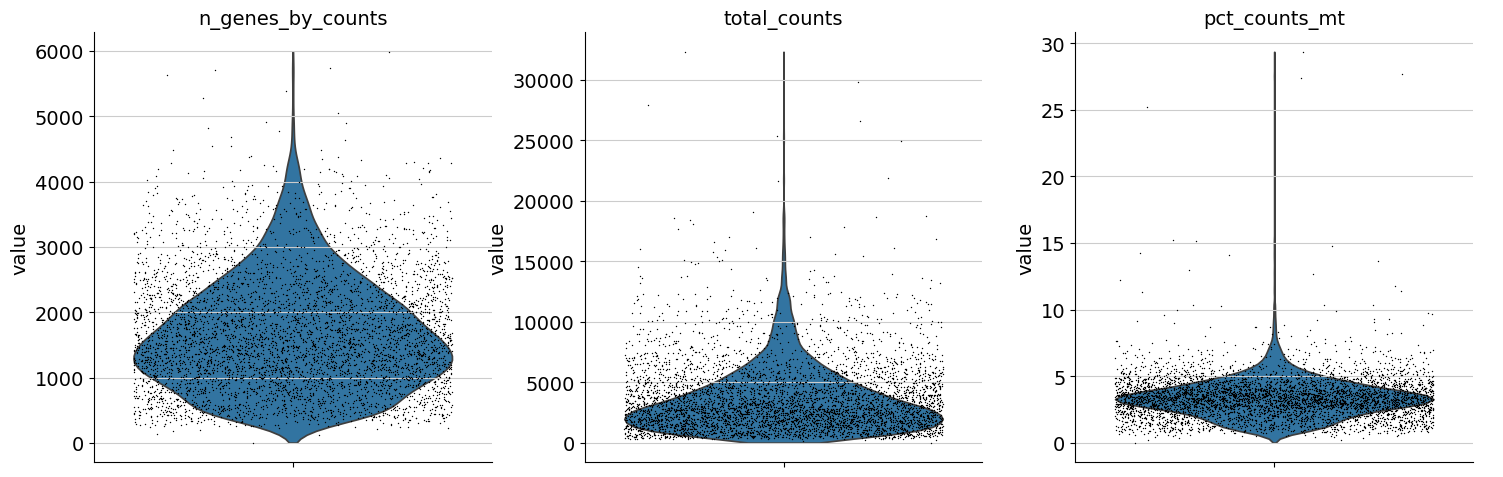

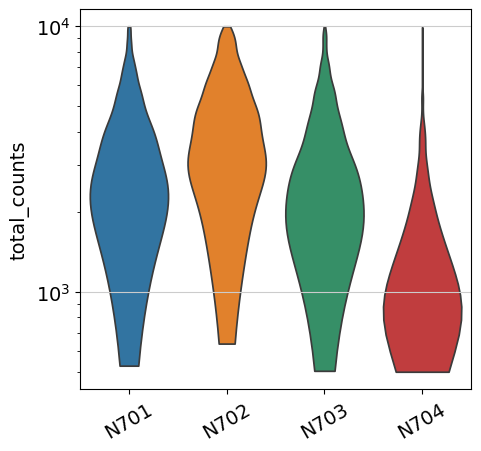

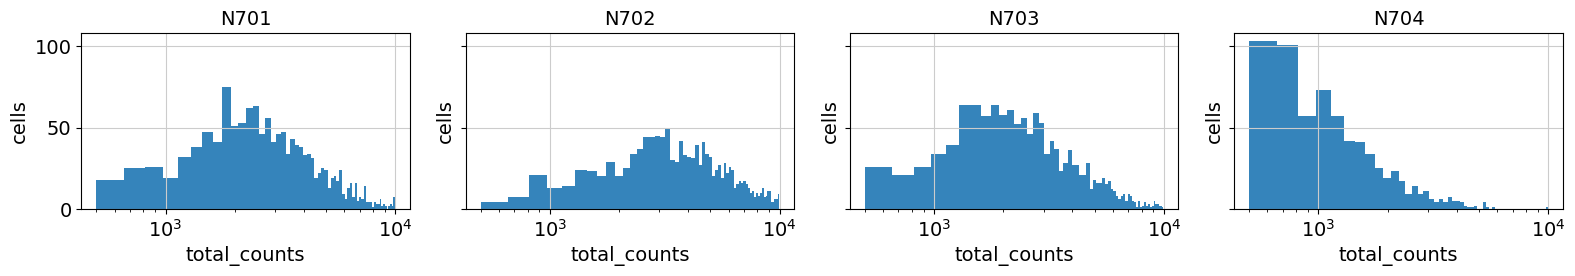

In [4]:
adata.var['mt'] = adata.var_names.str.startswith(('MT-', 'mt-'))
adata.var['rb'] = adata.var_names.str.startswith(('RPS', 'RPL'))
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'rb'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

qc_mask = (
    (adata.obs['total_counts'] >= 500)
    & (adata.obs['total_counts'] <= 10000)
    & (adata.obs['pct_counts_mt'] < 7.5)
)
adata = adata[qc_mask, :].copy()

sc.pl.violin(adata,
             keys='total_counts',
             groupby='sample',
             log=True,
             stripplot=False,
             rotation=30,
             multi_panel=False)

df = adata.obs[['sample','total_counts']].dropna().copy()
order = df['sample'].astype('category').cat.categories.tolist()

fig, axes = plt.subplots(1, len(order), figsize=(4*len(order), 3), sharex=True, sharey=True)
if len(order) == 1:
    axes = [axes]

bins = np.histogram_bin_edges(df['total_counts'].values, bins=60)
for ax, s in zip(axes, order):
    x = df.loc[df['sample'] == s, 'total_counts'].values
    ax.hist(x, bins=bins, alpha=0.9)
    ax.set_title(str(s))
    ax.set_xlabel('total_counts')
    ax.set_ylabel('cells')
    ax.set_xscale('log')

plt.tight_layout()
plt.show()


AnnData object with n_obs × n_vars = 3953 × 21693
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'chronopack', 'sample_colors'


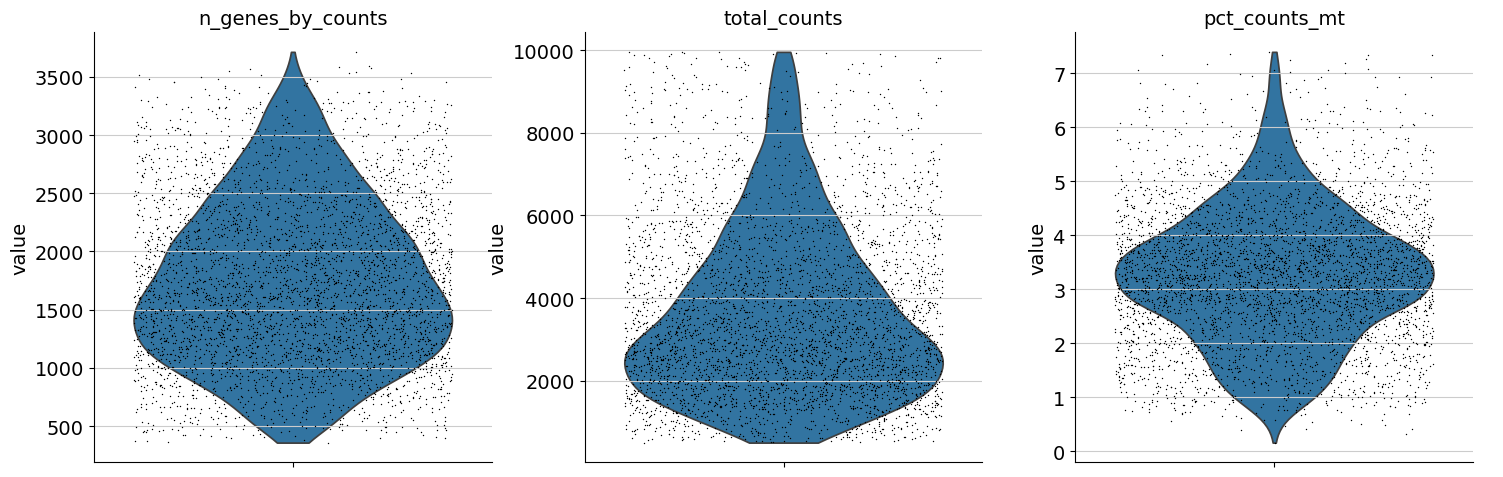

In [5]:
adata = adata[adata.obs['sample'] != 'N704', :].copy() # low quality RT batch
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

adata = adata[adata.obs['n_genes_by_counts'] >= 500, :].copy()
sc.pp.filter_genes(adata, min_cells=3)
print(adata)


In [6]:
sc.pp.scrublet(adata, batch_key="sample")
adata = adata[~adata.obs['predicted_doublet'], :]
print(adata.shape)


(3915, 21693)


# Standard processing

In [7]:
cell_cycle_genes = [x.strip() for x in open('../resources/regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]


In [8]:
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
adata.layers['cpm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['log1p'] = adata.X.copy()


01_PreprocessDatasets.ipynb:cell-10:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.


In [9]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat",
    subset=False,
)

sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata_hvg = adata[:, (adata.var.highly_variable & ~np.isin(adata.var.index, list(cell_cycle_genes)))]


/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


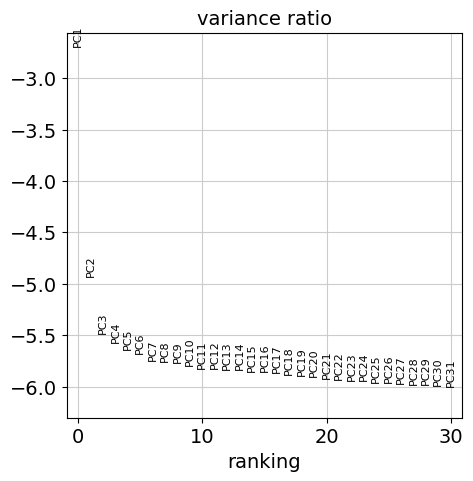

In [10]:
sc.pp.regress_out(adata_hvg, ['total_counts'])
sc.pp.scale(adata_hvg)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=30, log=True)


01_PreprocessDatasets.ipynb:cell-13:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


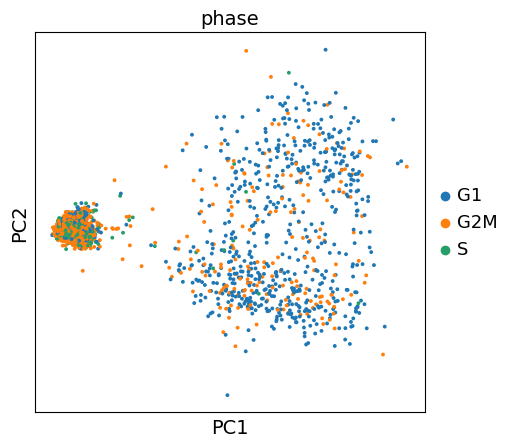

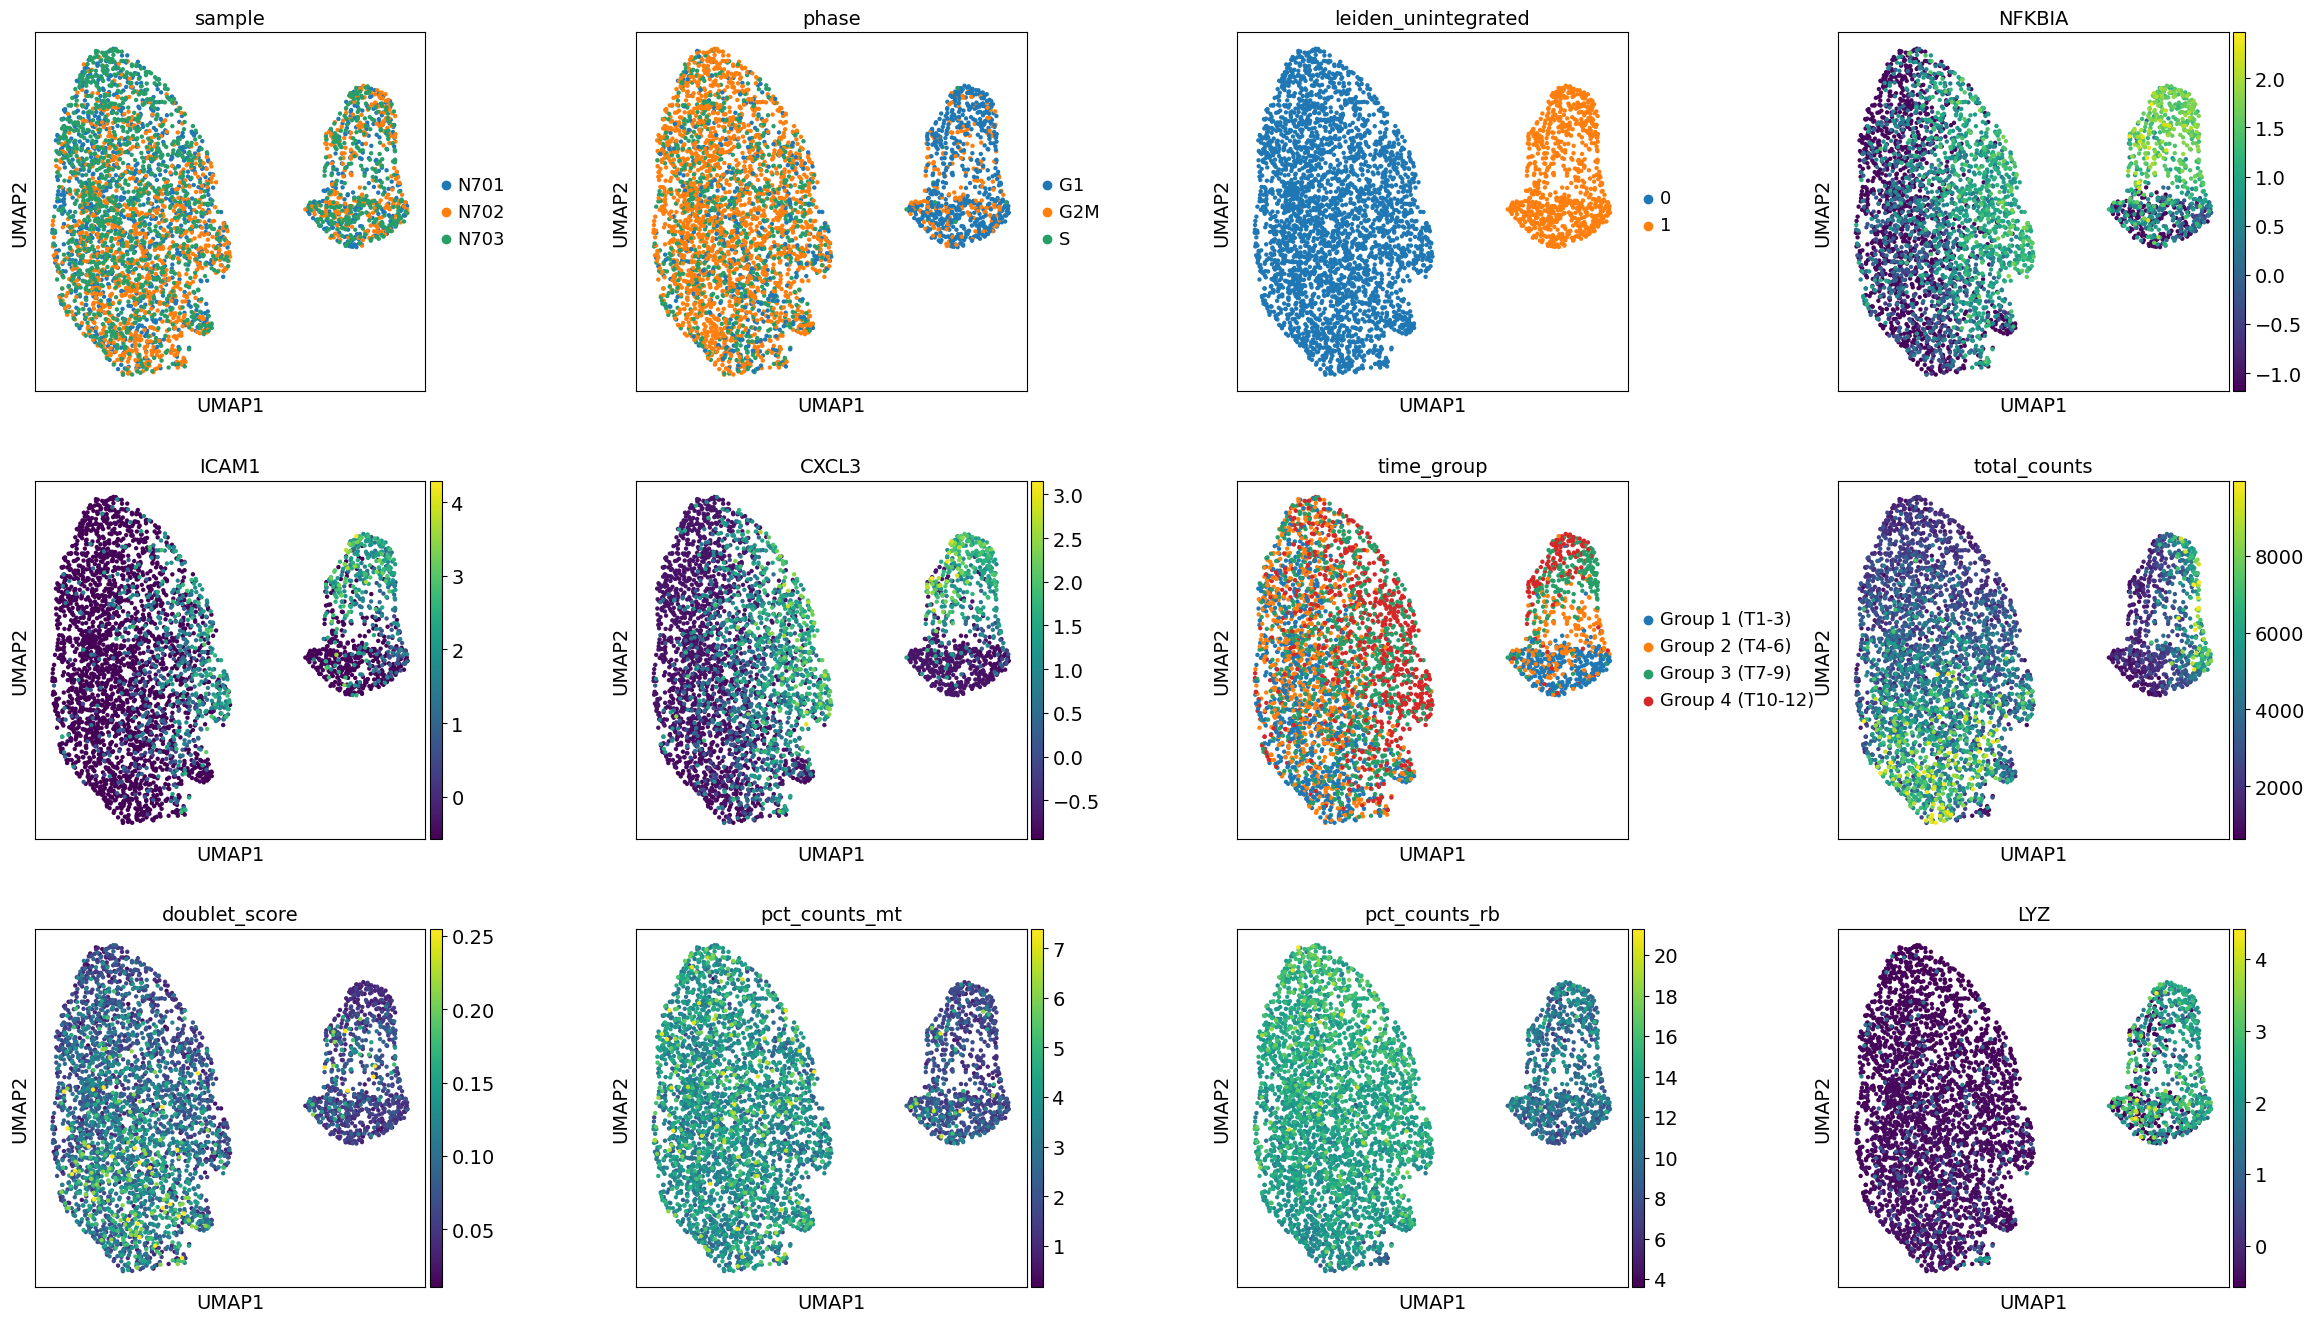

In [11]:
sc.pp.neighbors(adata_hvg, n_pcs=4, n_neighbors=30)
sc.tl.umap(adata_hvg)
sc.tl.leiden(adata_hvg, resolution=0.01, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata_hvg, color='phase')
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'leiden_unintegrated', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 
                         'doublet_score', 'pct_counts_mt', 'pct_counts_rb', 'LYZ'], wspace=0.4, size=40, ncols=4)


THP1 present: ['CD14', 'CD68', 'CD163', 'HLA-DRA', 'FCGR1A', 'MAFB', 'TNFAIP2']
THP1 missing: ['CD33', 'CD80', 'ITGAM']
K562 present: ['CD36', 'HBG1', 'CD69', 'IRF1']
K562 missing: ['CD34', 'CD43', 'GATA1', 'GYPA', 'TFRC']


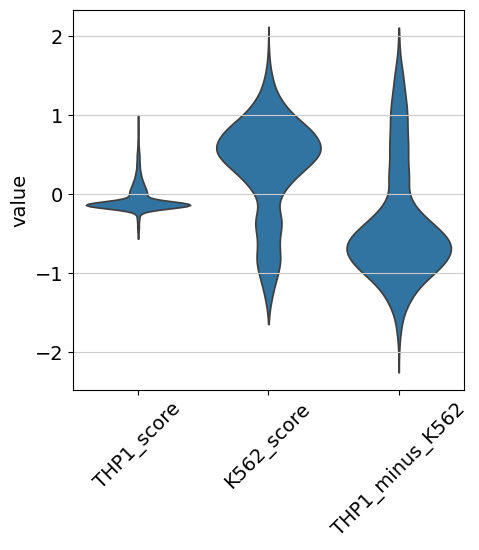

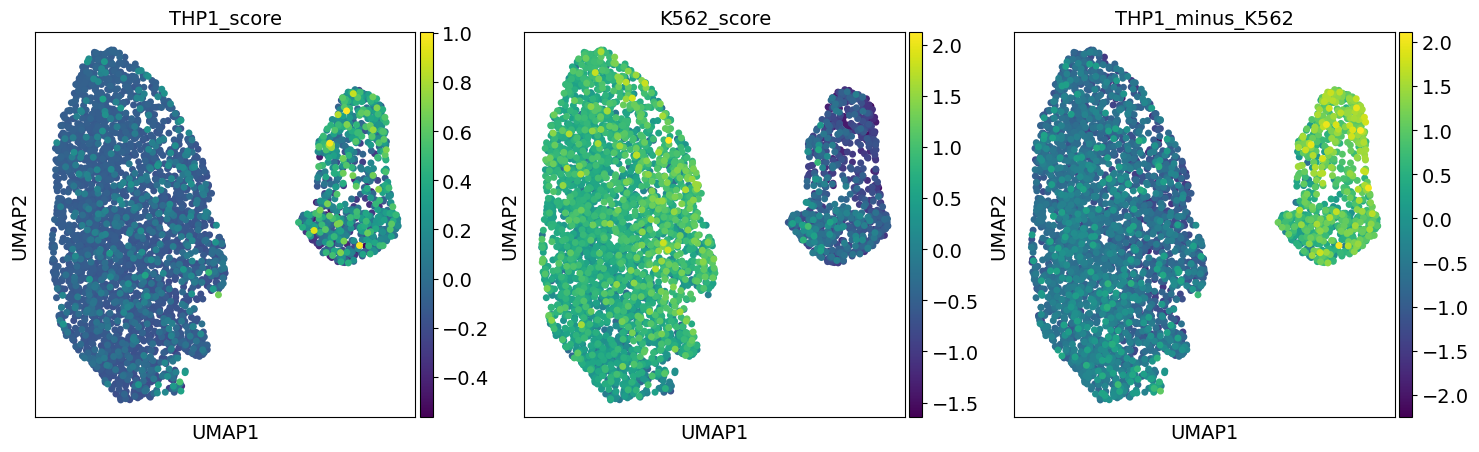

In [12]:
# -----------------------------
# 1) Marker lists (yours)
# -----------------------------
thp1_markers = [
    "CD14","CD11b","CD68","CD33","CD163","CD80","HLA-DR","FCGR1A","MAFB","TNFAIP2"
]
k562_markers = [
    "CD235a","CD71","CD34","CD43","CD36","GATA1","HBG1","CD69","IRF1","BCR-ABL"
]

# -----------------------------
# 2) Alias -> gene symbol fixes (edit if your var_names differ)
# -----------------------------
alias_map = {
    "CD11b": "ITGAM",
    "CD235a": "GYPA",
    "CD71": "TFRC",
    "HLA-DR": "HLA-DRA",   # you can also add HLA-DRB1 as separate marker if present
    "BCR-ABL": None,       # fusion; handle below
}

thp1_markers_symbols = [alias_map.get(g, g) for g in thp1_markers if alias_map.get(g, g) is not None]
k562_markers_symbols = [alias_map.get(g, g) for g in k562_markers if alias_map.get(g, g) is not None]
thp1_present = [g for g in thp1_markers_symbols if g in adata_hvg.var_names]
k562_present = [g for g in k562_markers_symbols if g in adata_hvg.var_names]
thp1_missing = sorted(set(thp1_markers_symbols) - set(thp1_present))
k562_missing = sorted(set(k562_markers_symbols) - set(k562_present))

print("THP1 present:", thp1_present)
print("THP1 missing:", thp1_missing)
print("K562 present:", k562_present)
print("K562 missing:", k562_missing)

# Optional: add BCR and ABL1 if both exist and you want that proxy
if ("BCR" in adata_hvg.var_names) and ("ABL1" in adata_hvg.var_names):
    # only add if not already included
    if "BCR" not in k562_present:  k562_present.append("BCR")
    if "ABL1" not in k562_present: k562_present.append("ABL1")

# -----------------------------
# 3) Score modules (Seurat-style)
#    - use_raw=True if you have adata_hvg.raw set to log-normalized counts you trust
# -----------------------------
sc.tl.score_genes(adata_hvg, thp1_present, score_name="THP1_score", use_raw=False, layer="log1p")
sc.tl.score_genes(adata_hvg, k562_present, score_name="K562_score", use_raw=False, layer="log1p")

# A simple combined discriminator
adata_hvg.obs["THP1_minus_K562"] = adata_hvg.obs["THP1_score"] - adata_hvg.obs["K562_score"]

# -----------------------------
# 4) Diagnostics: compare marker scores to current cell_type labels
# -----------------------------
# If cell_type labels have already been assigned:
if "cell_type" in adata_hvg.obs:
    print("\nMean scores by cell_type:")
    display(adata_hvg.obs.groupby("cell_type")[["THP1_score","K562_score","THP1_minus_K562"]].mean())

# Visualize
sc.pl.violin(
    adata_hvg,
    keys=["THP1_score","K562_score","THP1_minus_K562"],
    groupby="cell_type" if "cell_type" in adata_hvg.obs else None,
    rotation=45,
    stripplot=False,
)

# Optional: UMAP colored by scores if you have X_umap
if "X_umap" in adata_hvg.obsm:
    sc.pl.umap(adata_hvg, color=["THP1_score","K562_score","THP1_minus_K562"], size=100)


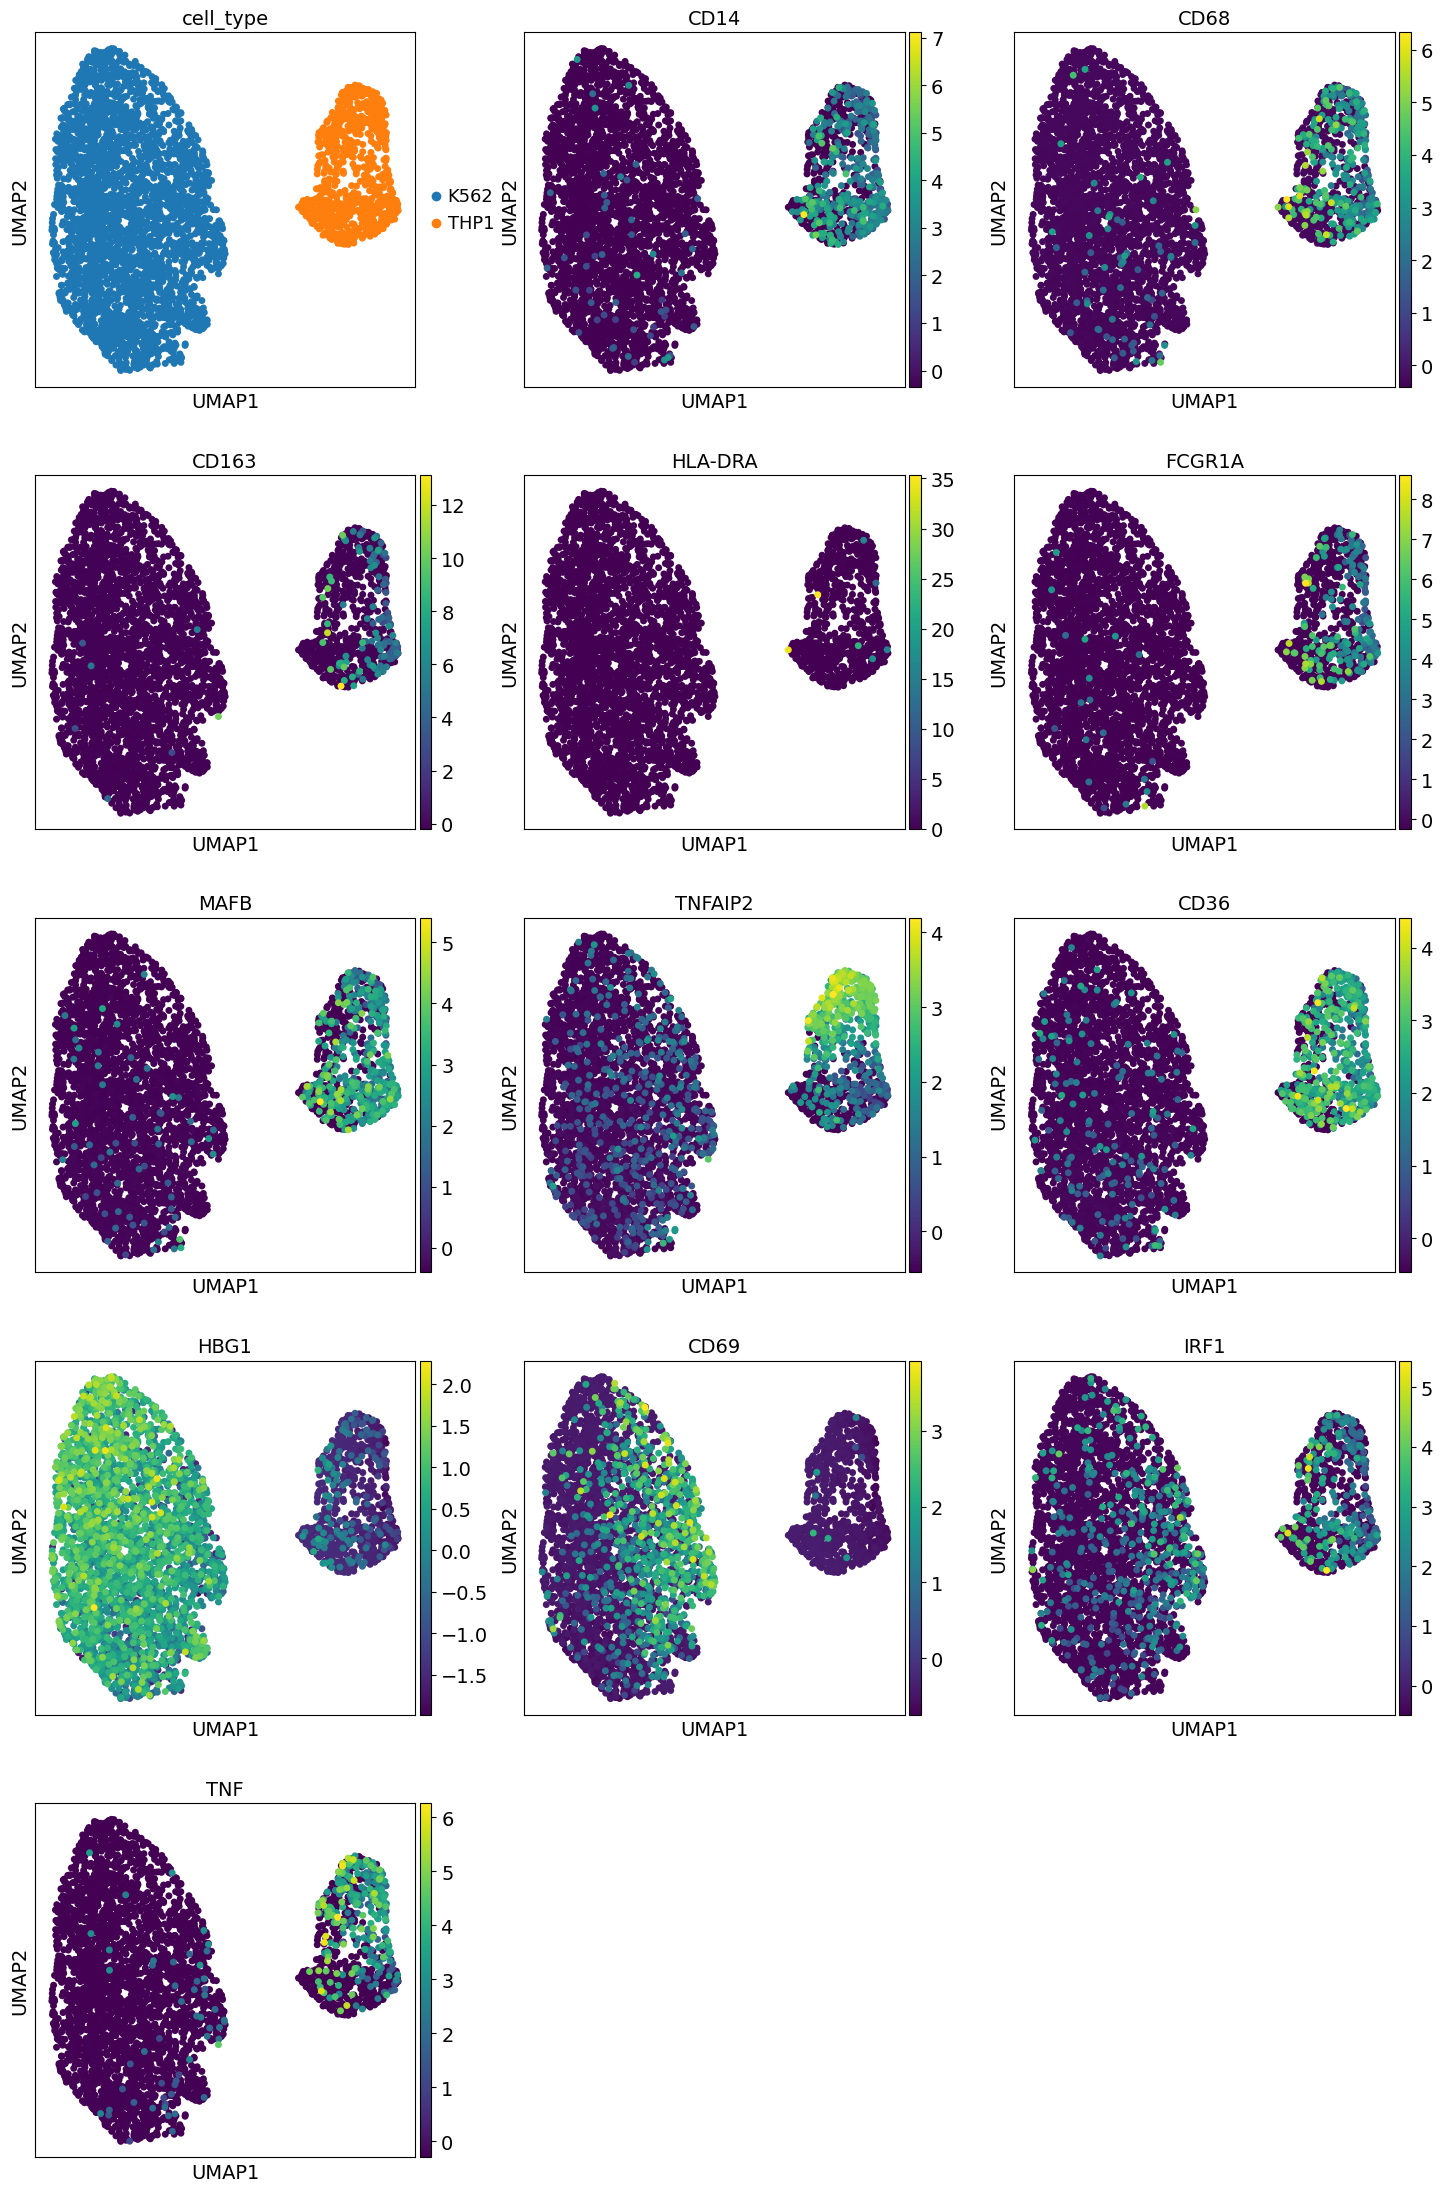

In [13]:
# The two coarse Leiden clusters separate the cell lines.
cell_type_by_cluster = {'0': 'K562', '1': 'THP1'}
adata_hvg.obs['cell_type'] = [cell_type_by_cluster.get(x) for x in adata_hvg.obs['leiden_unintegrated']]

lineage_marker_genes = thp1_present + k562_present
sc.pl.umap(adata_hvg, color=['cell_type'] + lineage_marker_genes + ['TNF'], ncols=3, cmap='viridis', gene_symbols=None, size=100)


# Save single-cell AnnData object

In [14]:
adata = adata[adata_hvg.obs.index, :]
adata.obsp = adata_hvg.obsp.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obs = adata_hvg.obs.copy()

print(adata)
print(adata_hvg)

cp.io.validate_preprocessed_adata(
    adata,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)
cp.io.validate_preprocessed_adata(
    adata_hvg,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)

adata.write_h5ad(EXP_DIR / 'output/adata_full.chk0.h5ad')
adata_hvg.write_h5ad(EXP_DIR / 'output/adata_hvg.chk0.h5ad')


AnnData object with n_obs × n_vars = 3915 × 21693
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_unintegrated', 'THP1_score', 'K562_score', 'THP1_minus_K562', 'cell_type'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'chronopack', 'sample_colors', 'scrublet', 'log1p', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', 'cpm', 'log1p'
    obsp: 'distances', 'connectivities'
AnnData object with n_obs × n_vars = 3915 × 1994
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', '